<a href="https://colab.research.google.com/github/Upandergarg/diabetes-prediction-using-ml/blob/main/Copy_of_DiabetiesAimlProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Import libraries

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [41]:
df = pd.read_csv("diabetes_dataset.csv")
df_eda = df.copy()
df.head()


,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0


In [42]:
df.shape

(100000, 16)

In [43]:
df.columns

Index(['year', 'gender', 'age', 'location', 'race:AfricanAmerican',
       'race:Asian', 'race:Caucasian', 'race:Hispanic', 'race:Other',
       'hypertension', 'heart_disease', 'smoking_history', 'bmi',
       'hbA1c_level', 'blood_glucose_level', 'diabetes'],
      dtype='object')

In [44]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   year                  100000 non-null  int64  
 1   gender                100000 non-null  object 
 2   age                   100000 non-null  float64
 3   location              100000 non-null  object 
 4   race:AfricanAmerican  100000 non-null  int64  
 5   race:Asian            100000 non-null  int64  
 6   race:Caucasian        100000 non-null  int64  
 7   race:Hispanic         100000 non-null  int64  
 8   race:Other            100000 non-null  int64  
 9   hypertension          100000 non-null  int64  
 10  heart_disease         100000 non-null  int64  
 11  smoking_history       100000 non-null  object 
 12  bmi                   100000 non-null  float64
 13  hbA1c_level           100000 non-null  float64
 14  blood_glucose_level   100000 non-null  int64  
 15  d

In [45]:
df.describe()

,year,age,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,bmi,hbA1c_level,blood_glucose_level,diabetes
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000
mean,2018.360820,41.885856,0.202230,0.200150,0.198760,0.19888,0.199980,0.07485,0.039420,27.320767,5.527507,138.058060,0.085000
std,1.345239,22.516840,0.401665,0.400114,0.399069,0.39916,0.399987,0.26315,0.194593,6.636783,1.070672,40.708136,0.278883
min,2015.000000,0.080000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,10.010000,3.500000,80.000000,0.000000
25%,2019.000000,24.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,23.630000,4.800000,100.000000,0.000000
50%,2019.000000,43.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,27.320000,5.800000,140.000000,0.000000
75%,2019.000000,60.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.00000,0.000000,29.580000,6.200000,159.000000,0.000000
max,2022.000000,80.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.00000,1.000000,95.690000,9.000000,300.000000,1.000000


Check Data Quality

In [46]:
df.isnull().sum()

,0
year,0
gender,0
age,0
location,0
race:AfricanAmerican,0
race:Asian,0
race:Caucasian,0
race:Hispanic,0
race:Other,0
hypertension,0


to check if any column has 0 val

In [47]:
(df == 0).sum()

,0
year,0
gender,0
age,0
location,0
race:AfricanAmerican,79777
race:Asian,79985
race:Caucasian,80124
race:Hispanic,80112
race:Other,80002
hypertension,92515


Class imbalance means one target class (0 or 1) has significantly more records than the other.

In [48]:
print(df["diabetes"].value_counts())

print("\nPercentage:")
print(df["diabetes"].value_counts(normalize=True) * 100)

diabetes
0    91500
1     8500
Name: count, dtype: int64

Percentage:
diabetes
0    91.5
1     8.5
Name: proportion, dtype: float64


Data Cleaning

Checking missing values

In [49]:
# Check missing values in each column
df.isnull().sum()

,0
year,0
gender,0
age,0
location,0
race:AfricanAmerican,0
race:Asian,0
race:Caucasian,0
race:Hispanic,0
race:Other,0
hypertension,0


In [50]:
# Separate numerical and categorical columns
numerical_cols = df.select_dtypes(include=np.number).columns
categorical_cols = df.select_dtypes(include="object").columns

# Fill missing numerical values
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values
for col in categorical_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

checking for duplicated rows

In [51]:
print("Duplicates before cleaning:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after cleaning:", df.duplicated().sum())

Duplicates before cleaning: 14
Duplicates after cleaning: 0


In [52]:
# Remove unnecessary spaces
for col in categorical_cols:
    df[col] = df[col].str.strip()

print("Gender categories:")
print(df["gender"].value_counts())

print("\nSmoking history categories:")
print(df["smoking_history"].value_counts())

Gender categories:
gender
Female    58546
Male      41422
Other        18
Name: count, dtype: int64

Smoking history categories:
smoking_history
No Info        35806
never          35091
former          9352
current         9286
not current     6447
ever            4004
Name: count, dtype: int64


In [53]:
# Check binary columns
for col in ["hypertension", "heart_disease", "diabetes"]:
    print(col)
    print(df[col].value_counts())

hypertension
hypertension
0    92501
1     7485
Name: count, dtype: int64
heart_disease
heart_disease
0    96044
1     3942
Name: count, dtype: int64
diabetes
diabetes
0    91486
1     8500
Name: count, dtype: int64


In [54]:
df.isnull().sum()

,0
year,0
gender,0
age,0
location,0
race:AfricanAmerican,0
race:Asian,0
race:Caucasian,0
race:Hispanic,0
race:Other,0
hypertension,0


In [55]:
print("FINAL CLEANED DATASET")

print("\nDataset Shape:")
print(df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nDataset Information:")
df.info()

print("\nFirst 10 Records:")
display(df.head(10))

FINAL CLEANED DATASET

Dataset Shape:
(99986, 16)

Missing Values:
year                    0
gender                  0
age                     0
location                0
race:AfricanAmerican    0
race:Asian              0
race:Caucasian          0
race:Hispanic           0
race:Other              0
hypertension            0
heart_disease           0
smoking_history         0
bmi                     0
hbA1c_level             0
blood_glucose_level     0
diabetes                0
dtype: int64

Duplicate Records:
0

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 99986 entries, 0 to 99999
Data columns (total 16 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  99986 non-null  int64  
 1   gender                99986 non-null  object 
 2   age                   99986 non-null  float64
 3   location              99986 non-null  object 
 4   race:AfricanAmerican  99986 non-null  int64  

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0
5,2016,Male,66.0,Alabama,0,0,1,0,0,0,0,not current,27.32,5.7,159,0
6,2015,Female,49.0,Alabama,0,0,1,0,0,0,0,current,24.34,5.7,80,0
7,2016,Female,15.0,Alabama,0,0,0,0,1,0,0,No Info,20.98,5.0,155,0
8,2016,Male,51.0,Alabama,1,0,0,0,0,0,0,never,38.14,6.0,100,0
9,2015,Male,42.0,Alabama,0,0,1,0,0,0,0,No Info,27.32,5.7,160,0


check invalid values

final dataset

In [56]:
df.shape

(99986, 16)

In [57]:
df.head()

,year,gender,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,smoking_history,bmi,hbA1c_level,blood_glucose_level,diabetes
0,2020,Female,32.0,Alabama,0,0,0,0,1,0,0,never,27.32,5.0,100,0
1,2015,Female,29.0,Alabama,0,1,0,0,0,0,0,never,19.95,5.0,90,0
2,2015,Male,18.0,Alabama,0,0,0,0,1,0,0,never,23.76,4.8,160,0
3,2015,Male,41.0,Alabama,0,0,1,0,0,0,0,never,27.32,4.0,159,0
4,2016,Female,52.0,Alabama,1,0,0,0,0,0,0,never,23.75,6.5,90,0


Categorical Encoding – One-Hot Encoding
Your categorical columns are gender and smoking_history.

In [58]:
# Categorical Encoding

df = pd.get_dummies(
    df,
    columns=["gender", "smoking_history"],
    dtype=int
)

df.head()

,year,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,...,diabetes,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,2020,32.0,Alabama,0,0,0,0,1,0,0,...,0,1,0,0,0,0,0,0,1,0
1,2015,29.0,Alabama,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,1,0
2,2015,18.0,Alabama,0,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,1,0
3,2015,41.0,Alabama,0,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
4,2016,52.0,Alabama,1,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,1,0


In [59]:
print(df.columns)

Index(['year', 'age', 'location', 'race:AfricanAmerican', 'race:Asian',
       'race:Caucasian', 'race:Hispanic', 'race:Other', 'hypertension',
       'heart_disease', 'bmi', 'hbA1c_level', 'blood_glucose_level',
       'diabetes', 'gender_Female', 'gender_Male', 'gender_Other',
       'smoking_history_No Info', 'smoking_history_current',
       'smoking_history_ever', 'smoking_history_former',
       'smoking_history_never', 'smoking_history_not current'],
      dtype='object')


In [60]:
df.describe()

,year,age,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,bmi,...,diabetes,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
count,99986.000000,99986.000000,99986.000000,99986.000000,99986.000000,99986.000000,99986.000000,99986.000000,99986.000000,99986.000000,...,99986.000000,99986.000000,99986.000000,99986.000000,99986.000000,99986.000000,99986.000000,99986.000000,99986.000000,99986.000000
mean,2018.360731,41.885930,0.202238,0.200098,0.198758,0.198898,0.200008,0.074860,0.039426,27.320767,...,0.085012,0.585542,0.414278,0.000180,0.358110,0.092873,0.040046,0.093533,0.350959,0.064479
std,1.345312,22.516409,0.401671,0.400075,0.399067,0.399173,0.400008,0.263167,0.194606,6.637248,...,0.278901,0.492631,0.492599,0.013416,0.479447,0.290256,0.196067,0.291180,0.477273,0.245606
min,2015.000000,0.080000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,10.010000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2019.000000,24.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,23.630000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2019.000000,43.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,27.320000,...,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2019.000000,60.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,29.580000,...,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,2022.000000,80.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,95.690000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


Separate X, Y  

In [61]:
X = df.drop("diabetes", axis=1)
y = df["diabetes"]

In [62]:
# Separate Features and Target

X = df.drop("diabetes", axis=1)
y = df["diabetes"]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeatures:")
print(X.columns)

print("\nTarget:")
print(y.name)

X shape: (99986, 22)
y shape: (99986,)

Features:
Index(['year', 'age', 'location', 'race:AfricanAmerican', 'race:Asian',
       'race:Caucasian', 'race:Hispanic', 'race:Other', 'hypertension',
       'heart_disease', 'bmi', 'hbA1c_level', 'blood_glucose_level',
       'gender_Female', 'gender_Male', 'gender_Other',
       'smoking_history_No Info', 'smoking_history_current',
       'smoking_history_ever', 'smoking_history_former',
       'smoking_history_never', 'smoking_history_not current'],
      dtype='object')

Target:
diabetes


EDA->Exploratory data visualisation

Diabetes outcome distribution

Observation: The dataset contains both diabetic and non-diabetic individuals. Non-diabetic individuals are considerably more numerous, indicating class imbalance.

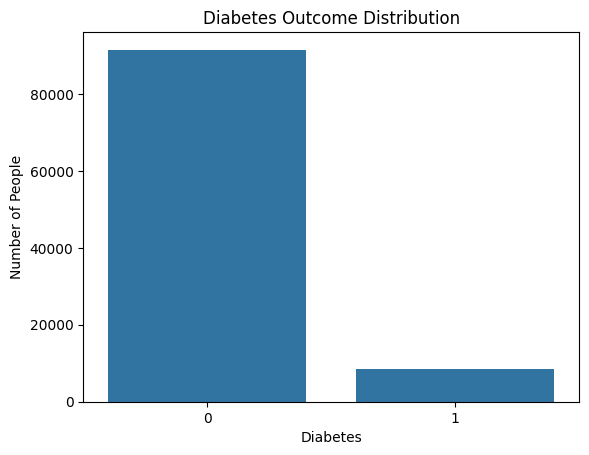

In [63]:
sns.countplot(data=df, x="diabetes")

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Diabetes")
plt.ylabel("Number of People")
plt.show()

Age distribution

Observation: The graph shows the distribution of ages among individuals in the dataset.

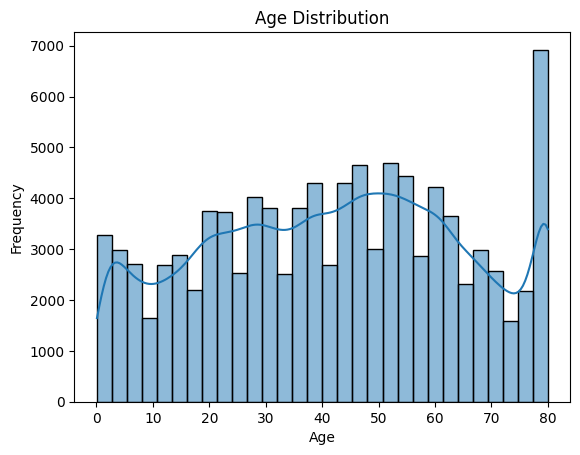

In [64]:
sns.histplot(data=df, x="age", bins=30, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

Blood glucose distribution

Observation: This graph helps understand the range and distribution of blood glucose levels across individuals.


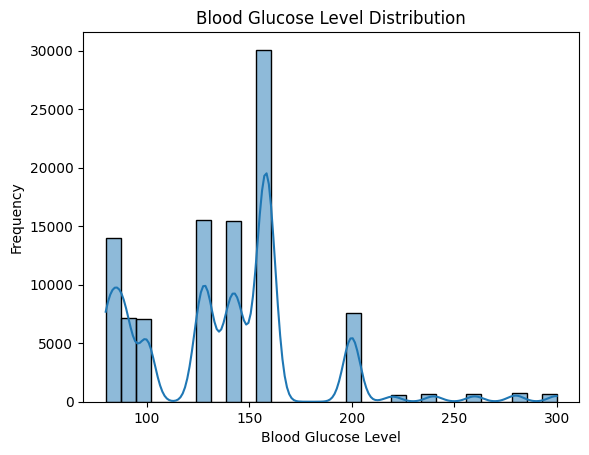

In [65]:
sns.histplot(data=df, x="blood_glucose_level", bins=30, kde=True)

plt.title("Blood Glucose Level Distribution")
plt.xlabel("Blood Glucose Level")
plt.ylabel("Frequency")
plt.show()

Blood glucose vs diabetes

Observation: Comparing blood glucose levels between diabetic and non-diabetic groups helps identify whether glucose levels differ across the two groups.

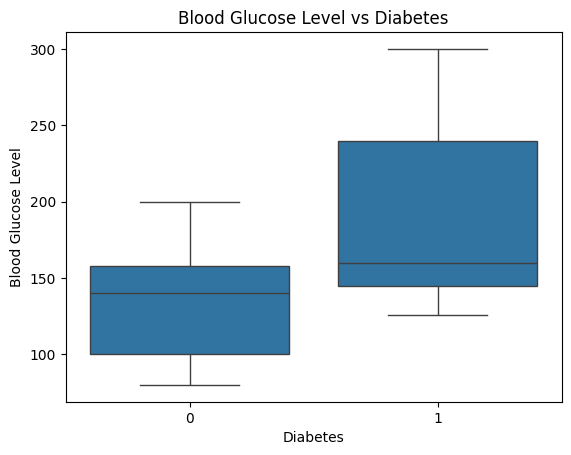

In [66]:
sns.boxplot(data=df, x="diabetes", y="blood_glucose_level")

plt.title("Blood Glucose Level vs Diabetes")
plt.xlabel("Diabetes")
plt.ylabel("Blood Glucose Level")
plt.show()

BMI vs diabetes

Observation: This visualization compares BMI distributions between diabetic and non-diabetic individuals.

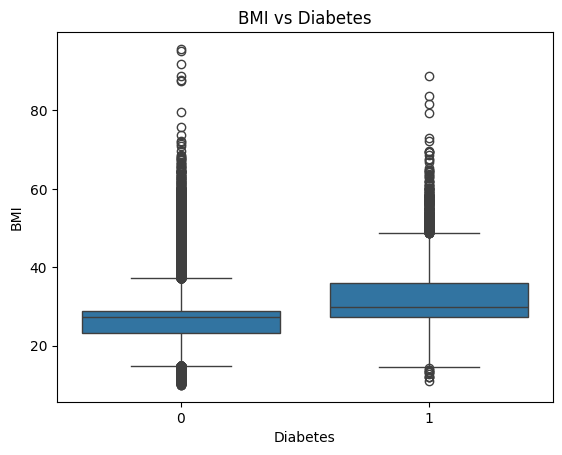

In [67]:
sns.boxplot(data=df, x="diabetes", y="bmi")

plt.title("BMI vs Diabetes")
plt.xlabel("Diabetes")
plt.ylabel("BMI")
plt.show()

Gender distribution

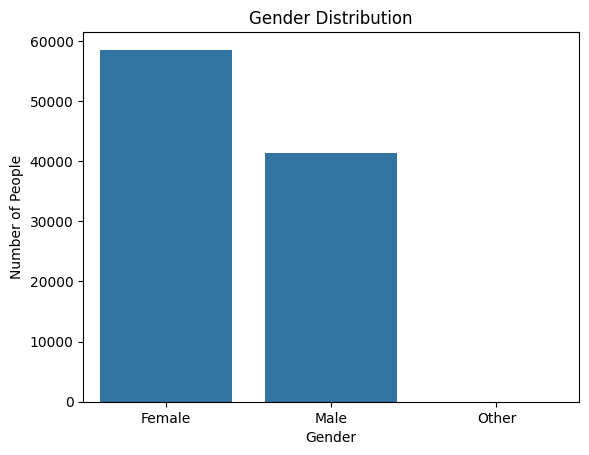

In [68]:
sns.countplot(data=df_eda, x="gender")
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of People")
plt.show()

Smoking history distribution

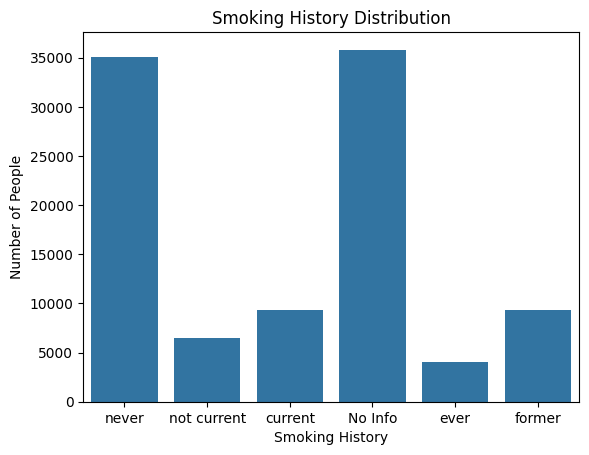

In [69]:
sns.countplot(data=df_eda, x="smoking_history")
plt.title("Smoking History Distribution")
plt.xlabel("Smoking History")
plt.ylabel("Number of People")
plt.show()

Correlation heatmap

We will calculate correlation between numerical columns only.

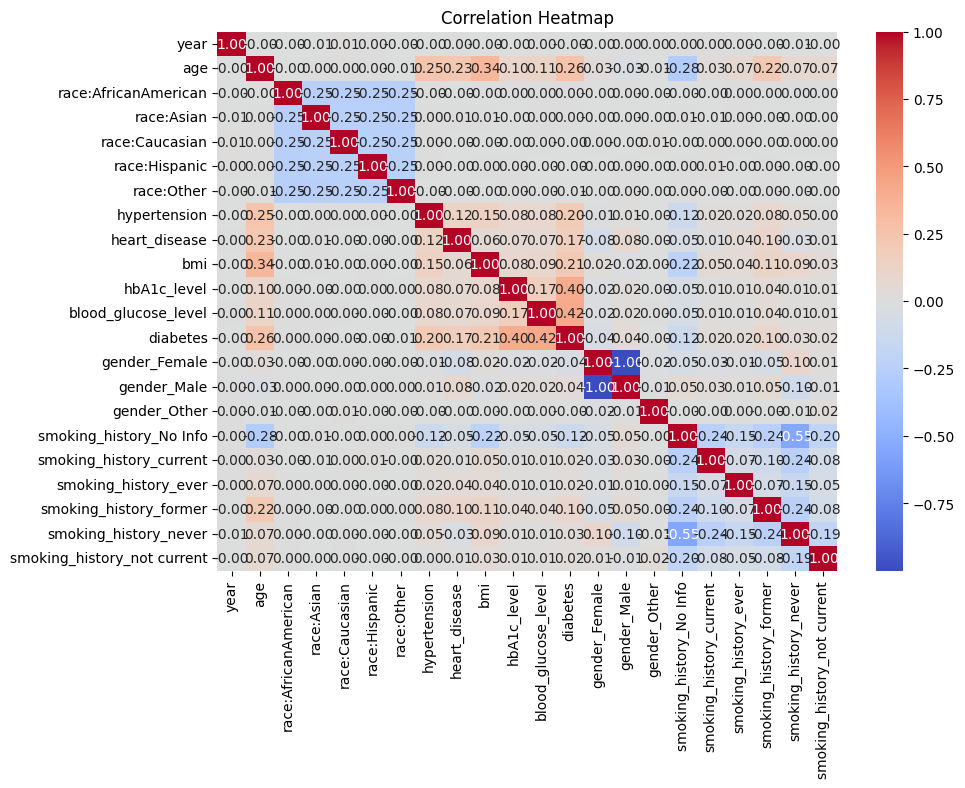

In [70]:
plt.figure(figsize=(10, 7))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

Final Pre-Processed Dataset

In [71]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nFirst 10 Rows:")
display(df.head(10))

Dataset Shape: (99986, 23)

Missing Values:
year                           0
age                            0
location                       0
race:AfricanAmerican           0
race:Asian                     0
race:Caucasian                 0
race:Hispanic                  0
race:Other                     0
hypertension                   0
heart_disease                  0
bmi                            0
hbA1c_level                    0
blood_glucose_level            0
diabetes                       0
gender_Female                  0
gender_Male                    0
gender_Other                   0
smoking_history_No Info        0
smoking_history_current        0
smoking_history_ever           0
smoking_history_former         0
smoking_history_never          0
smoking_history_not current    0
dtype: int64

Duplicate Rows:
0

First 10 Rows:


,year,age,location,race:AfricanAmerican,race:Asian,race:Caucasian,race:Hispanic,race:Other,hypertension,heart_disease,...,diabetes,gender_Female,gender_Male,gender_Other,smoking_history_No Info,smoking_history_current,smoking_history_ever,smoking_history_former,smoking_history_never,smoking_history_not current
0,2020,32.0,Alabama,0,0,0,0,1,0,0,...,0,1,0,0,0,0,0,0,1,0
1,2015,29.0,Alabama,0,1,0,0,0,0,0,...,0,1,0,0,0,0,0,0,1,0
2,2015,18.0,Alabama,0,0,0,0,1,0,0,...,0,0,1,0,0,0,0,0,1,0
3,2015,41.0,Alabama,0,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
4,2016,52.0,Alabama,1,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,1,0
5,2016,66.0,Alabama,0,0,1,0,0,0,0,...,0,0,1,0,0,0,0,0,0,1
6,2015,49.0,Alabama,0,0,1,0,0,0,0,...,0,1,0,0,0,1,0,0,0,0
7,2016,15.0,Alabama,0,0,0,0,1,0,0,...,0,1,0,0,1,0,0,0,0,0
8,2016,51.0,Alabama,1,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
9,2015,42.0,Alabama,0,0,1,0,0,0,0,...,0,0,1,0,1,0,0,0,0,0


Train Test Split

In [72]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [73]:
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (79988, 22)
Testing Features: (19998, 22)
Training Target: (79988,)
Testing Target: (19998,)


In [74]:
print("Training data distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting data distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training data distribution:
diabetes
0    91.498725
1     8.501275
Name: proportion, dtype: float64

Testing data distribution:
diabetes
0    91.49915
1     8.50085
Name: proportion, dtype: float64


In [75]:
print("X_train:", "X_train" in globals())
print("X_test:", "X_test" in globals())
print("y_train:", "y_train" in globals())
print("y_test:", "y_test" in globals())

X_train: True
X_test: True
y_train: True
y_test: True


In [76]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# Separate numerical and categorical features
numerical_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

# Preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# KNN Model
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

# Train the model
knn_model.fit(X_train, y_train)

print("KNN Model trained successfully!")

KNN Model trained successfully!
